![Project Logo](images/cardekho_logo.png)

## Cardekho EDA

In [28]:
# import the important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [29]:
car_dekho_raw =  pd.read_csv('data/raw/Car details v3.csv')

In [30]:
car_dekho_raw.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,Maruti Wagon R LXI DUO BSIII,2007,96000,175000,LPG,Individual,Manual,First Owner,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,Toyota Etios VXD,2011,350000,90000,Diesel,Individual,Manual,First Owner,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,Ford Figo Diesel Celebration Edition,2013,200000,169000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0


In [31]:
car_dekho_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


In [32]:
car_dekho_raw.describe(include='number')

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [33]:
car_dekho_raw.describe(exclude='number')

,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,8128,8128,8128,8128,8128,7907,7907,7913,7906
unique,2058,4,3,2,5,393,121,322,441
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm
freq,129,4402,6766,7078,5289,225,1017,377,530


In [34]:
car_dekho_cleaned = car_dekho_raw.copy()

In [35]:
car_dekho_cleaned['year'] = pd.to_datetime(car_dekho_cleaned['year'], format='%Y')

In [36]:
car_dekho_cleaned['mileage_numeric'] = car_dekho_cleaned['mileage'].str.replace(' kmpl', '').str.replace(' km/kg', '').astype(float)

In [37]:
car_dekho_cleaned['engine_numeric'] = car_dekho_cleaned['engine'].str.replace(' cc', '').str.replace(' CC','').astype(float)

In [38]:
car_dekho_cleaned['max_power_numeric'] = car_dekho_cleaned['max_power'].str.lower().str.replace(' bhp', '').str.strip()

In [39]:
car_dekho_cleaned.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats', 'mileage_numeric', 'engine_numeric', 'max_power_numeric'],
      dtype='str')

In [40]:
for col in car_dekho_cleaned.columns:
    values = car_dekho_cleaned[col].value_counts(dropna=False)
    print(f"Column: {col}")
    print(values, end="\n\n")

Column: name
name
Maruti Swift Dzire VDI                          129
Maruti Alto 800 LXI                              82
Maruti Alto LXi                                  71
BMW X4 M Sport X xDrive20d                       62
Maruti Swift VDI                                 61
                                               ... 
Maruti Celerio ZXI AMT BSIV                       1
Tata Bolt Revotron XM                             1
Tata Manza Aura (ABS) Safire BS IV                1
Tata Nexon 1.5 Revotorq XT                        1
Toyota Innova 2.5 GX (Diesel) 8 Seater BS IV      1
Name: count, Length: 2058, dtype: int64

Column: year
year
2017-01-01    1018
2016-01-01     859
2018-01-01     807
2015-01-01     776
2013-01-01     670
2012-01-01     651
2014-01-01     621
2011-01-01     592
2019-01-01     583
2010-01-01     394
2009-01-01     246
2008-01-01     214
2007-01-01     183
2006-01-01     124
2005-01-01      97
2020-01-01      74
2004-01-01      62
2003-01-01      49
2002-01-0

In [41]:
for col in car_dekho_cleaned.columns:
    print(f"Column: {col}")
    print(car_dekho_cleaned[col].isna().sum(), car_dekho_cleaned[col].isna().mean()*100, end="\n\n")

Column: name
0 0.0

Column: year
0 0.0

Column: selling_price
0 0.0

Column: km_driven
0 0.0

Column: fuel
0 0.0

Column: seller_type
0 0.0

Column: transmission
0 0.0

Column: owner
0 0.0

Column: mileage
221 2.718996062992126

Column: engine
221 2.718996062992126

Column: max_power
215 2.645177165354331

Column: torque
222 2.731299212598425

Column: seats
221 2.718996062992126

Column: mileage_numeric
221 2.718996062992126

Column: engine_numeric
221 2.718996062992126

Column: max_power_numeric
215 2.645177165354331



In [42]:
missing_table = pd.DataFrame({'Missing_Count': car_dekho_cleaned.isna().sum(), 'Missing_Percentage': round(car_dekho_cleaned.isna().mean() * 100,2)}).sort_values(by='Missing_Percentage', ascending=False) 
display(missing_table[missing_table['Missing_Percentage'] > 0])

,Missing_Count,Missing_Percentage
torque,222,2.73
mileage,221,2.72
engine,221,2.72
seats,221,2.72
mileage_numeric,221,2.72
engine_numeric,221,2.72
max_power,215,2.65
max_power_numeric,215,2.65


In [43]:
car_dekho_missing = car_dekho_cleaned[car_dekho_cleaned['torque'].isna()]
car_dekho_missing.isna().sum().sort_values(ascending=False)

torque               222
mileage              221
engine               221
seats                221
mileage_numeric      221
engine_numeric       221
max_power            215
max_power_numeric    215
name                   0
year                   0
selling_price          0
km_driven              0
fuel                   0
seller_type            0
transmission           0
owner                  0
dtype: int64

In [44]:
for i in car_dekho_missing.columns:
    print(f"Column: {i}")
    print(car_dekho_missing[i].value_counts(dropna=False), end="\n\n")

Column: name
name
Maruti Swift VDI BSIV          23
Maruti Swift 1.3 VXi           14
Toyota Etios GD                10
Maruti Omni E 8 Str STD         9
Maruti Swift VDI BSIV W ABS     7
                               ..
Ford Ikon 1.8 D                 1
Peugeot 309 GLD                 1
Hyundai Santro Xing XO          1
Toyota Etios VD                 1
Hyundai Accent Gvs              1
Name: count, Length: 86, dtype: int64

Column: year
year
2012-01-01    30
2011-01-01    22
2006-01-01    22
2005-01-01    21
2010-01-01    19
2009-01-01    15
2008-01-01    13
2003-01-01    12
2004-01-01    11
2007-01-01    10
2017-01-01     8
2002-01-01     8
2000-01-01     7
1999-01-01     4
2001-01-01     4
2016-01-01     3
2013-01-01     2
1997-01-01     2
2015-01-01     1
1983-01-01     1
1996-01-01     1
1994-01-01     1
1995-01-01     1
1998-01-01     1
1991-01-01     1
2018-01-01     1
2014-01-01     1
Name: count, dtype: int64

Column: selling_price
selling_price
200000    12
130000     8
120

In [45]:
car_dekho_cleaned.dropna(inplace=True)

In [46]:
car_dekho_cleaned.isna().sum()

name                 0
year                 0
selling_price        0
km_driven            0
fuel                 0
seller_type          0
transmission         0
owner                0
mileage              0
engine               0
max_power            0
torque               0
seats                0
mileage_numeric      0
engine_numeric       0
max_power_numeric    0
dtype: int64

In [47]:
car_dekho_cleaned.info()

<class 'pandas.DataFrame'>
Index: 7906 entries, 0 to 8127
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   name               7906 non-null   str           
 1   year               7906 non-null   datetime64[us]
 2   selling_price      7906 non-null   int64         
 3   km_driven          7906 non-null   int64         
 4   fuel               7906 non-null   str           
 5   seller_type        7906 non-null   str           
 6   transmission       7906 non-null   str           
 7   owner              7906 non-null   str           
 8   mileage            7906 non-null   str           
 9   engine             7906 non-null   str           
 10  max_power          7906 non-null   str           
 11  torque             7906 non-null   str           
 12  seats              7906 non-null   float64       
 13  mileage_numeric    7906 non-null   float64       
 14  engine_numeric     7906 

In [48]:
car_dekho_cleaned['max_power_numeric'] = pd.to_numeric(car_dekho_cleaned['max_power_numeric'], errors='coerce')

In [49]:
car_dekho_cleaned.info()

<class 'pandas.DataFrame'>
Index: 7906 entries, 0 to 8127
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   name               7906 non-null   str           
 1   year               7906 non-null   datetime64[us]
 2   selling_price      7906 non-null   int64         
 3   km_driven          7906 non-null   int64         
 4   fuel               7906 non-null   str           
 5   seller_type        7906 non-null   str           
 6   transmission       7906 non-null   str           
 7   owner              7906 non-null   str           
 8   mileage            7906 non-null   str           
 9   engine             7906 non-null   str           
 10  max_power          7906 non-null   str           
 11  torque             7906 non-null   str           
 12  seats              7906 non-null   float64       
 13  mileage_numeric    7906 non-null   float64       
 14  engine_numeric     7906 

In [50]:
car_dekho_cleaned.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_numeric,engine_numeric,max_power_numeric
0,Maruti Swift Dzire VDI,2014-01-01,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,23.40,1248.0,74.00
1,Skoda Rapid 1.5 TDI Ambition,2014-01-01,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,21.14,1498.0,103.52
2,Honda City 2017-2020 EXi,2006-01-01,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,17.70,1497.0,78.00
3,Hyundai i20 Sportz Diesel,2010-01-01,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,23.00,1396.0,90.00
4,Maruti Swift VXI BSIII,2007-01-01,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,16.10,1298.0,88.20


In [51]:
for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    car_dekho_cleaned[col] = car_dekho_cleaned[col].astype('category')

In [52]:
car_dekho_cleaned.info()

<class 'pandas.DataFrame'>
Index: 7906 entries, 0 to 8127
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   name               7906 non-null   str           
 1   year               7906 non-null   datetime64[us]
 2   selling_price      7906 non-null   int64         
 3   km_driven          7906 non-null   int64         
 4   fuel               7906 non-null   category      
 5   seller_type        7906 non-null   category      
 6   transmission       7906 non-null   category      
 7   owner              7906 non-null   category      
 8   mileage            7906 non-null   str           
 9   engine             7906 non-null   str           
 10  max_power          7906 non-null   str           
 11  torque             7906 non-null   str           
 12  seats              7906 non-null   float64       
 13  mileage_numeric    7906 non-null   float64       
 14  engine_numeric     7906 

In [53]:
car_dekho_cleaned = car_dekho_cleaned.drop([ 'mileage', 'engine', 'max_power'], axis=1)

In [60]:
car_dekho_cleaned['brand'] = car_dekho_cleaned['name'].str.split(' ').str[0]

In [62]:
car_dekho_cleaned.insert(0,'brand',car_dekho_cleaned.pop('brand'))

In [63]:
car_dekho_cleaned.head()

,brand,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,torque,seats,mileage_numeric,engine_numeric,max_power_numeric
0,Maruti,Maruti Swift Dzire VDI,2014-01-01,450000,145500,Diesel,Individual,Manual,First Owner,190Nm@ 2000rpm,5.0,23.40,1248.0,74.00
1,Skoda,Skoda Rapid 1.5 TDI Ambition,2014-01-01,370000,120000,Diesel,Individual,Manual,Second Owner,250Nm@ 1500-2500rpm,5.0,21.14,1498.0,103.52
2,Honda,Honda City 2017-2020 EXi,2006-01-01,158000,140000,Petrol,Individual,Manual,Third Owner,"12.7@ 2,700(kgm@ rpm)",5.0,17.70,1497.0,78.00
3,Hyundai,Hyundai i20 Sportz Diesel,2010-01-01,225000,127000,Diesel,Individual,Manual,First Owner,22.4 kgm at 1750-2750rpm,5.0,23.00,1396.0,90.00
4,Maruti,Maruti Swift VXI BSIII,2007-01-01,130000,120000,Petrol,Individual,Manual,First Owner,"11.5@ 4,500(kgm@ rpm)",5.0,16.10,1298.0,88.20


In [64]:
car_dekho_cleaned.describe(include='number').round(2)

,selling_price,km_driven,seats,mileage_numeric,engine_numeric,max_power_numeric
count,7906.00,7906.00,7906.00,7906.00,7906.00,7906.00
mean,649813.72,69188.66,5.42,19.42,1458.71,91.59
std,813582.75,56792.30,0.96,4.04,503.89,35.75
min,29999.00,1.00,2.00,0.00,624.00,32.80
25%,270000.00,35000.00,5.00,16.78,1197.00,68.05
50%,450000.00,60000.00,5.00,19.30,1248.00,82.00
75%,690000.00,95425.00,5.00,22.32,1582.00,102.00
max,10000000.00,2360457.00,14.00,42.00,3604.00,400.00


In [ ]:
car_dekho_cleaned.describe(exclude=['number', 'datetime']).round(2)

,brand,name,fuel,seller_type,transmission,owner,torque
count,7906,7906,7906,7906,7906,7906,7906
unique,31,1982,4,3,2,5,441
top,Maruti,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,190Nm@ 2000rpm
freq,2367,129,4299,6563,6865,5215,530


In [66]:
numeric_columns = car_dekho_cleaned.select_dtypes(include=['number']).columns
categorical_columns = car_dekho_cleaned.select_dtypes(include=['category']).columns

In [78]:
for i in categorical_columns:
    order = car_dekho_cleaned[i].value_counts().index
    
    print(f"Column: {i}")
    print(order, end="\n\n")

Column: fuel
CategoricalIndex(['Diesel', 'Petrol', 'CNG', 'LPG'], categories=['CNG', 'Diesel', 'LPG', 'Petrol'], ordered=False, dtype='category', name='fuel')

Column: seller_type
CategoricalIndex(['Individual', 'Dealer', 'Trustmark Dealer'], categories=['Dealer', 'Individual', 'Trustmark Dealer'], ordered=False, dtype='category', name='seller_type')

Column: transmission
CategoricalIndex(['Manual', 'Automatic'], categories=['Automatic', 'Manual'], ordered=False, dtype='category', name='transmission')

Column: owner
CategoricalIndex(['First Owner', 'Second Owner', 'Third Owner',
                  'Fourth & Above Owner', 'Test Drive Car'],
                 categories=['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner'], ordered=False, dtype='category', name='owner')



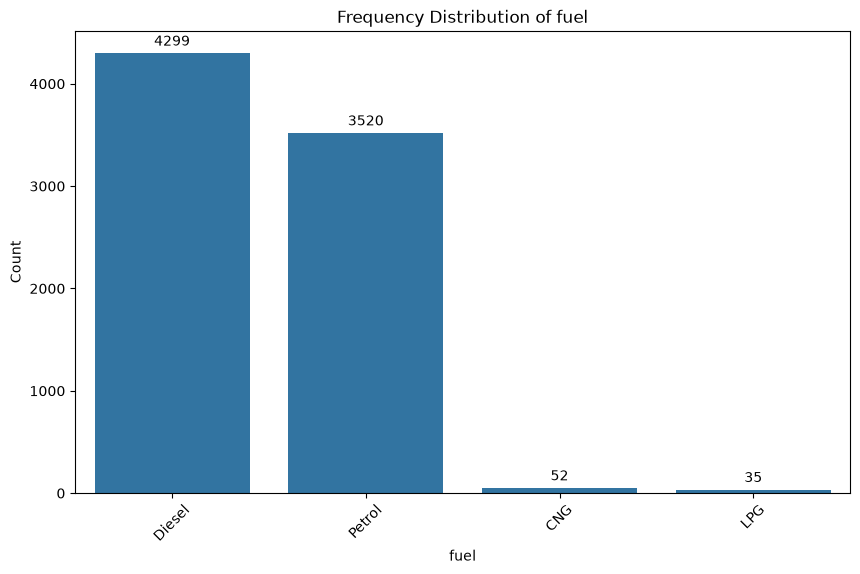

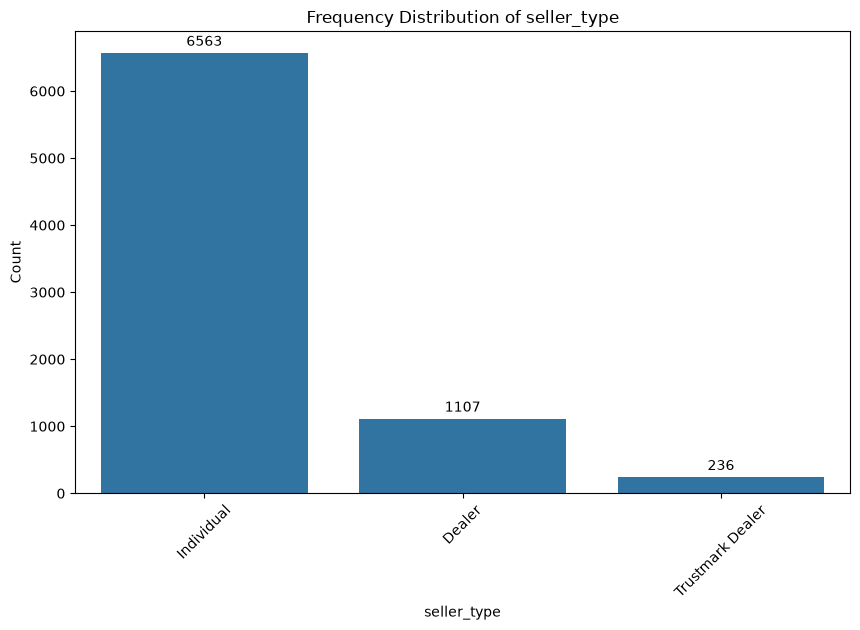

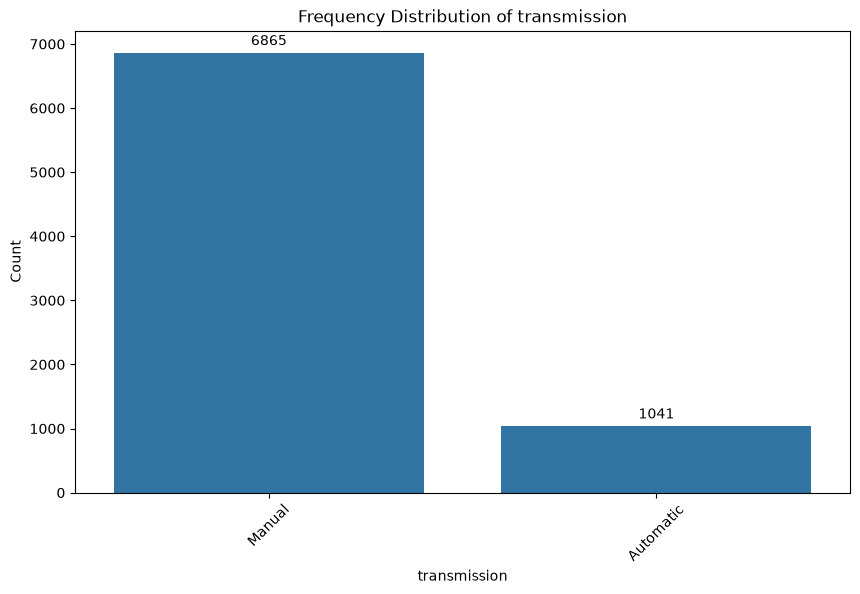

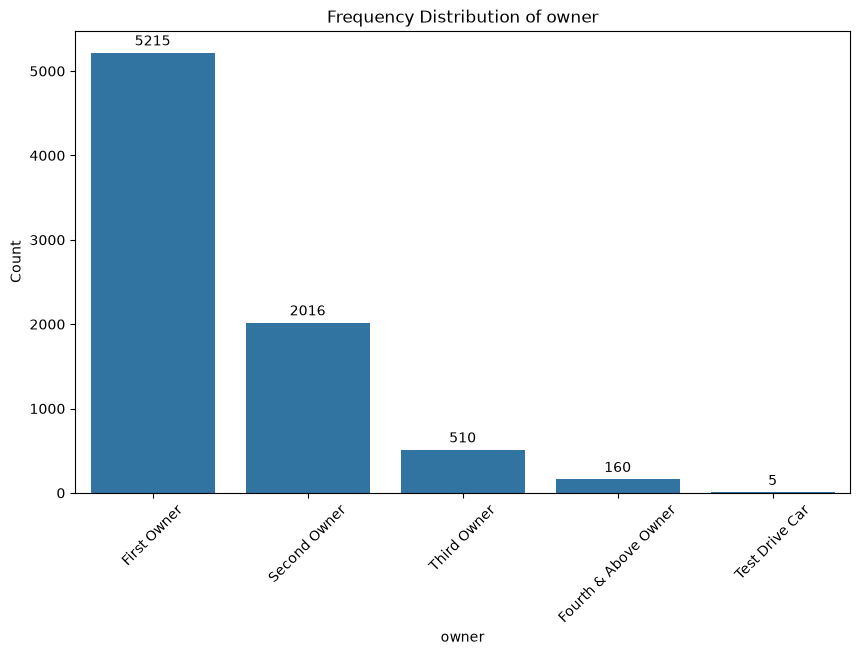

In [75]:
#frequency distribution of categorical variables
for i in categorical_columns:
    order = car_dekho_cleaned[i].value_counts().index
    plt.figure(figsize=(10, 6)) 
    ax = sns.countplot(x=i, data=car_dekho_cleaned, order=order)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    plt.xlabel(i)
    plt.ylabel('Count')
    plt.title(f'Frequency Distribution of {i}')
    plt.xticks(rotation=45)
    plt.show()

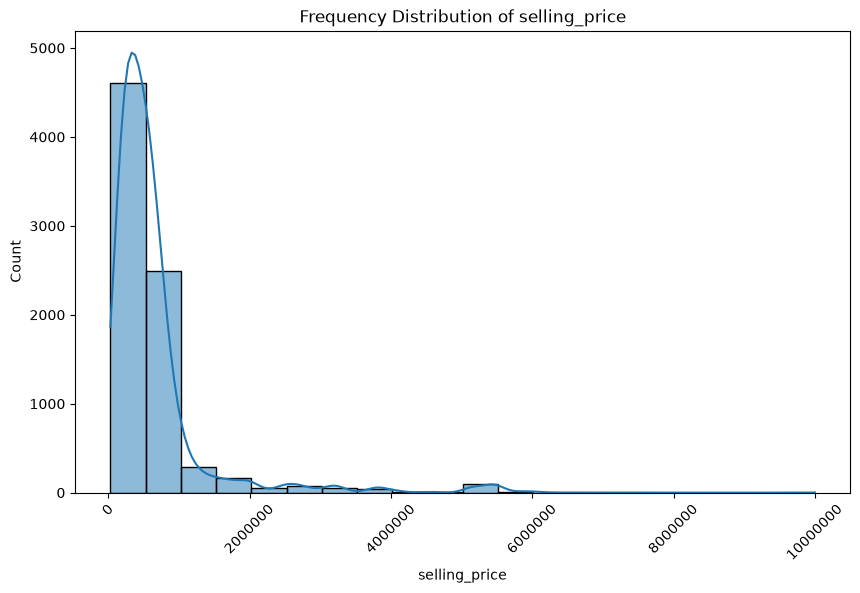

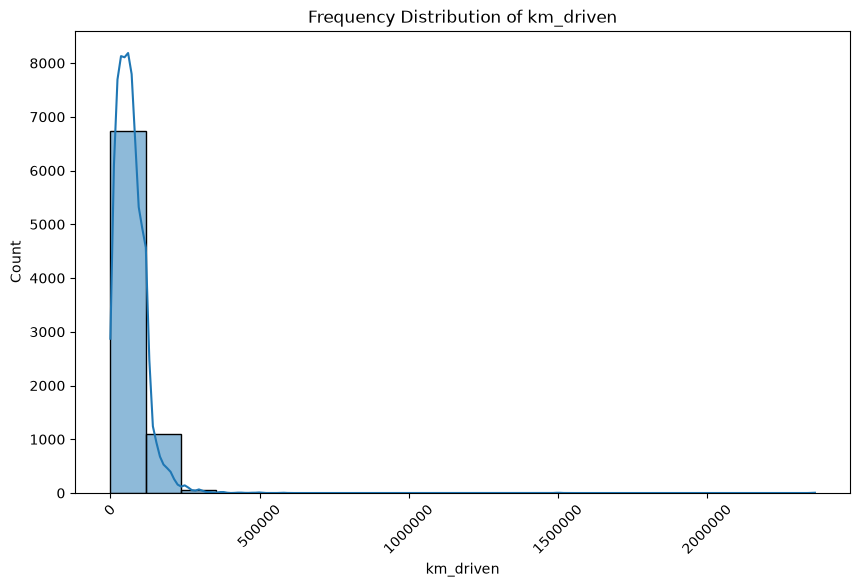

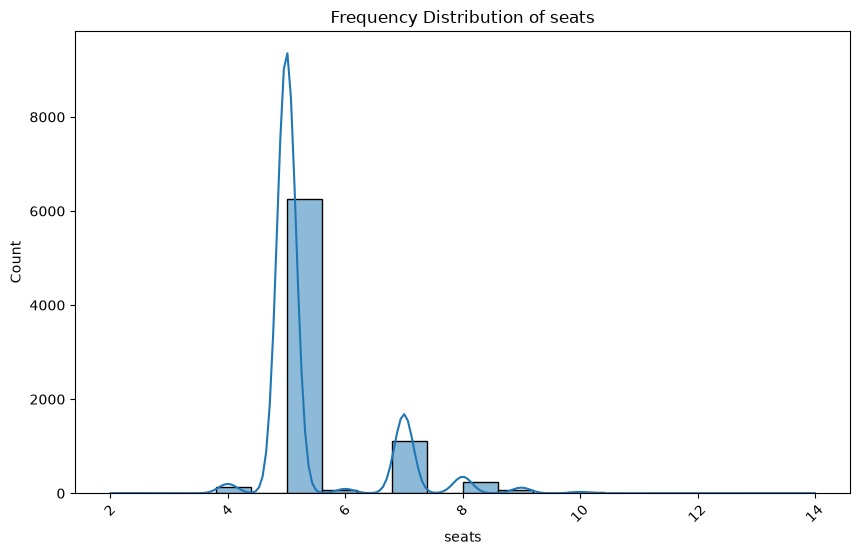

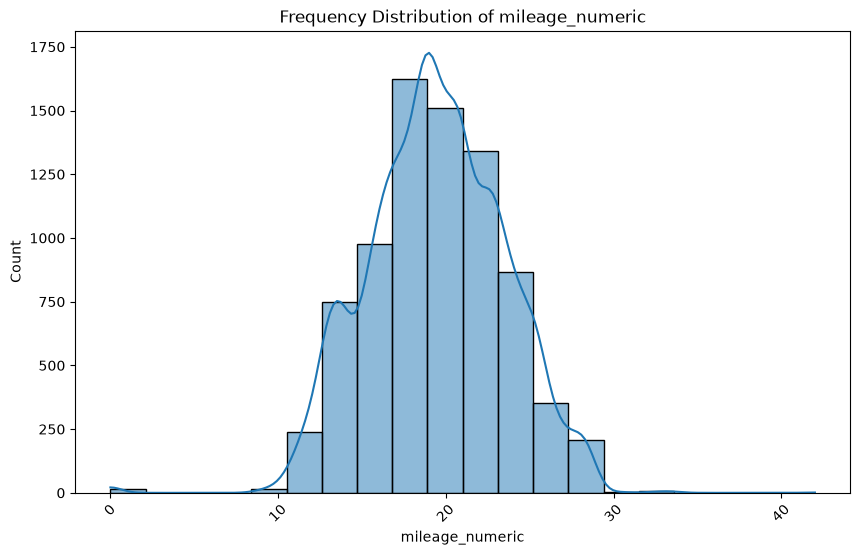

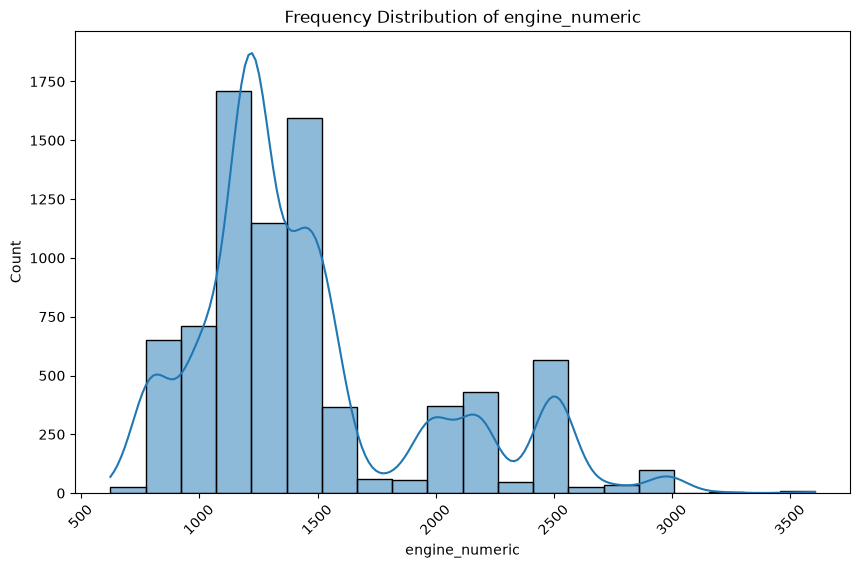

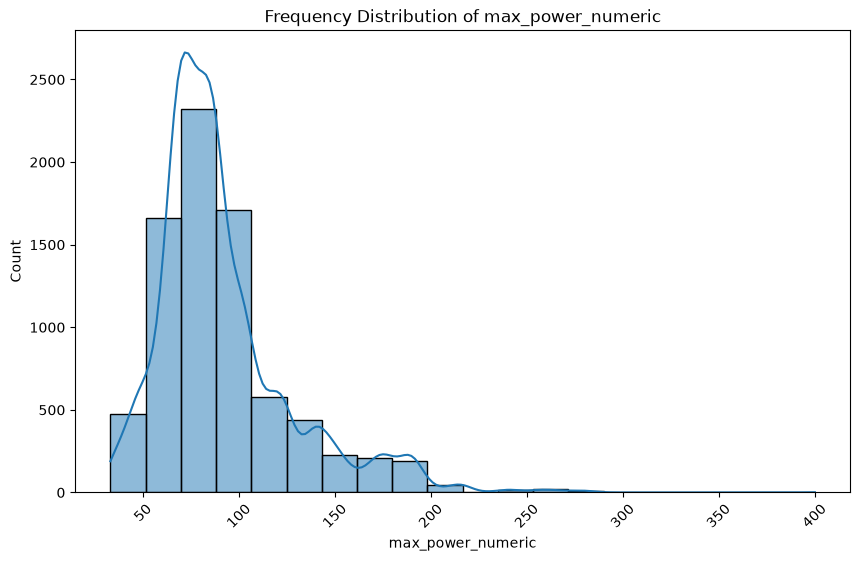

In [84]:
#frequency distribution of numeric variables
for i in numeric_columns:
    plt.figure(figsize=(10, 6)) 
    sns.histplot(car_dekho_cleaned[i], kde=True, bins=20)
    plt.xlabel(i)
    plt.ylabel('Count')
    plt.title(f'Frequency Distribution of {i}')
    plt.xticks(rotation=45)
    plt.ticklabel_format(axis="x", style="plain", useOffset=False)
    plt.show()
    plt.close()

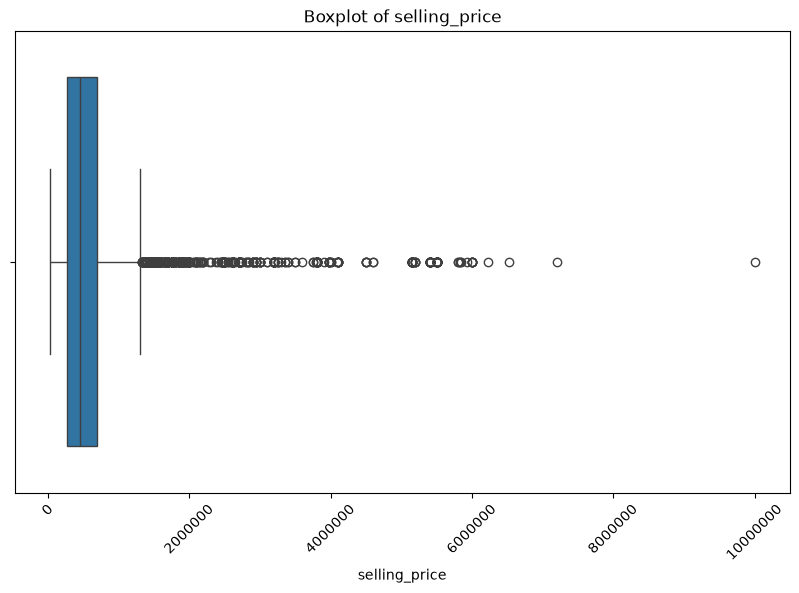

,left_3sd,Lower Limit,Upper Limit,right_3sd
0,-1.790935e+06,-360000.0,1320000.0,3.090562e+06


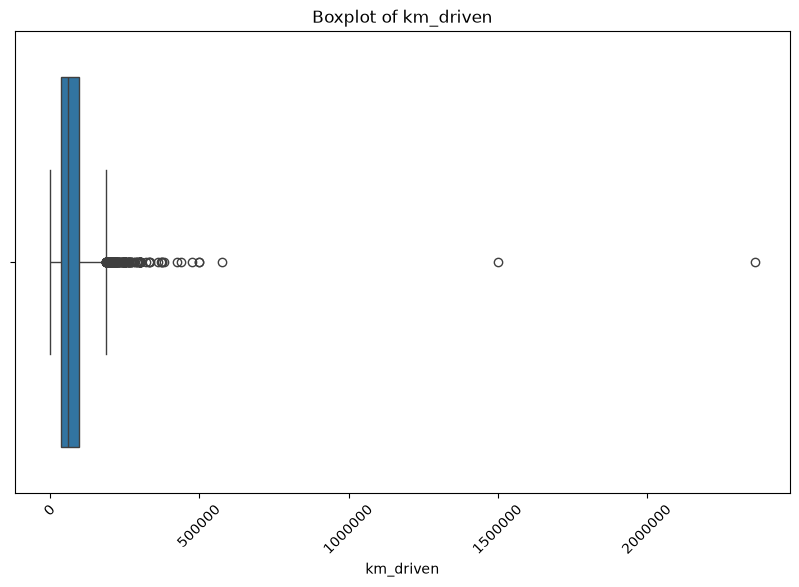

,left_3sd,Lower Limit,Upper Limit,right_3sd
0,-101188.229278,-55637.5,186062.5,239565.548782


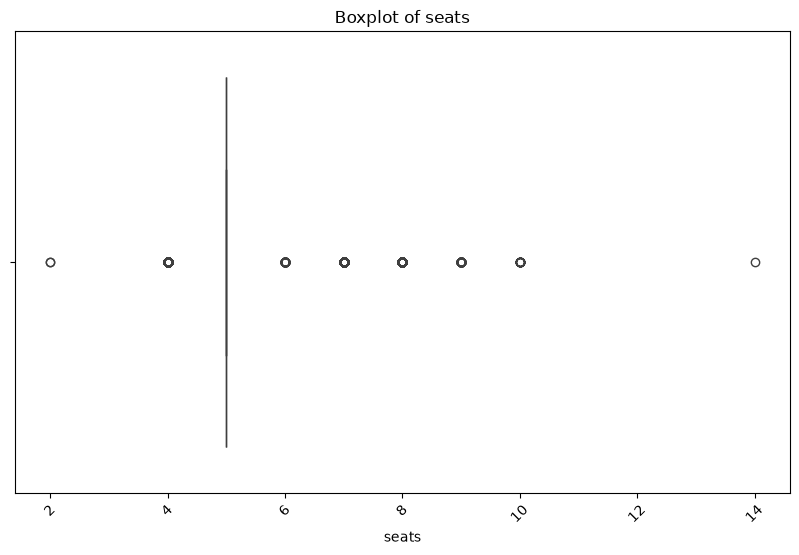

,left_3sd,Lower Limit,Upper Limit,right_3sd
0,2.538768,5.0,5.0,8.294017


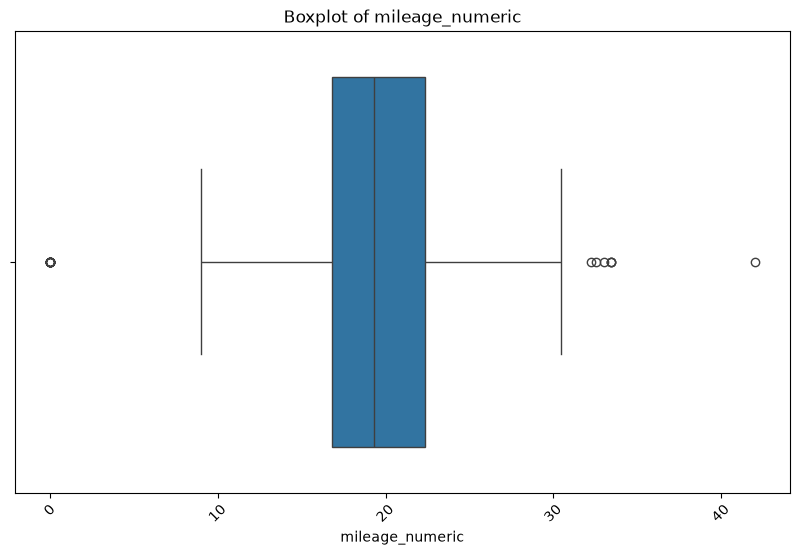

,left_3sd,Lower Limit,Upper Limit,right_3sd
0,7.311071,8.47,30.63,31.52865


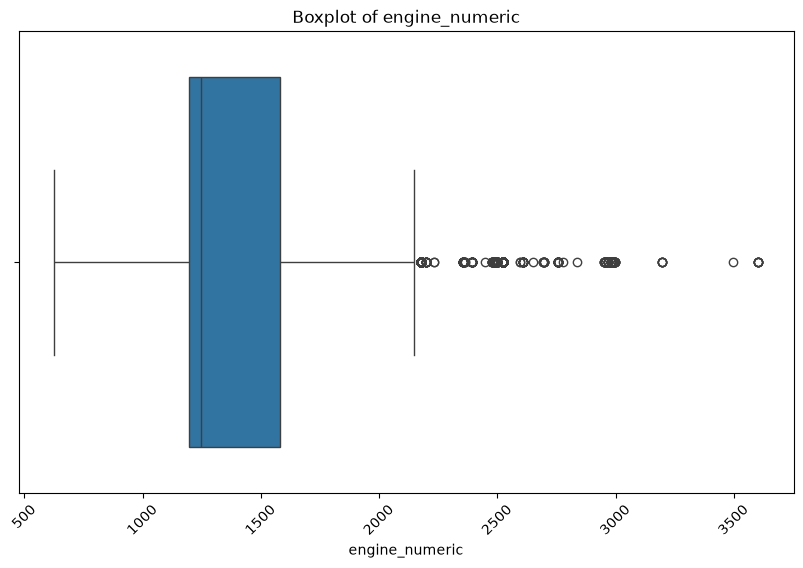

,left_3sd,Lower Limit,Upper Limit,right_3sd
0,-52.970342,619.5,2159.5,2970.387999


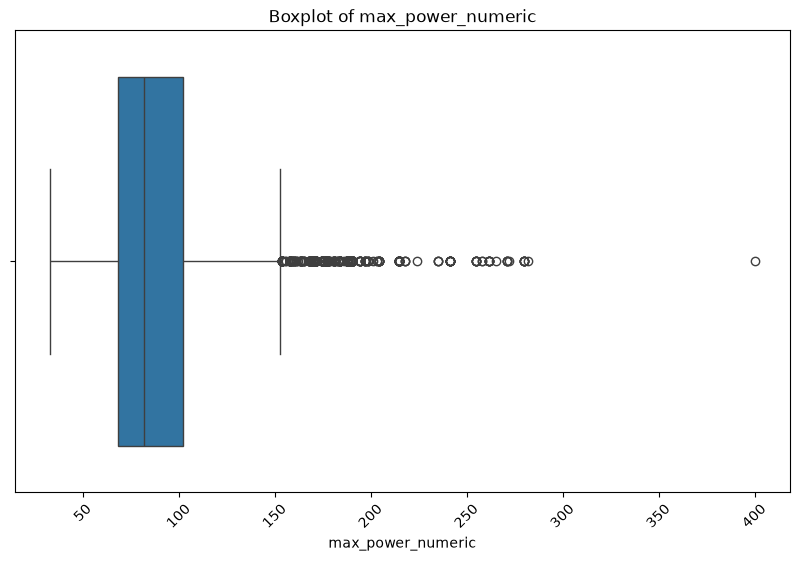

,left_3sd,Lower Limit,Upper Limit,right_3sd
0,-15.654275,17.125,152.925,198.829022


In [108]:
for col in numeric_columns:
    plt.figure(figsize=(10, 6)) 
    sns.boxplot(x=car_dekho_cleaned[col])
    plt.xlabel(col)
    plt.title(f'Boxplot of {col}')
    plt.xticks(rotation=45)
    plt.ticklabel_format(axis="x", style="plain", useOffset=False)
    plt.show()
    plt.close()
    ar = np.quantile(car_dekho_cleaned[col], [0.25, 0.75])
    q1 = ar[0]
    q3 = ar[1]
    iqr = q3 - q1
    outlier_limit = pd.DataFrame({'left_3sd':[car_dekho_cleaned[col].mean() - 3 * car_dekho_cleaned[col].std()], 'Lower Limit': [q1 - 1.5 * iqr], 'Upper Limit': [q3 + 1.5 * iqr],'right_3sd':[car_dekho_cleaned[col].mean() + 3 * car_dekho_cleaned[col].std()]})
    display(outlier_limit)

array([ 68.05, 102.  ])

In [115]:
car_brands = pd.DataFrame({'Brand': car_dekho_cleaned['brand'].value_counts().index, 'Count': car_dekho_cleaned['brand'].value_counts().values})
display(car_brands)

,Brand,Count
0,Maruti,2367
1,Hyundai,1360
2,Mahindra,758
3,Tata,719
4,Honda,466
5,Toyota,452
6,Ford,388
7,Chevrolet,230
8,Renault,228
9,Volkswagen,185


In [ ]:
# numer